# Part 1 — Best model: GMM-assisted self-training on reason embeddings

**Task.** Predict the five stopping-reason labels (Safety, Funding, Efficacy, Recruitment, Other) for
clinical trials where only 157 of 1,171 training trials are labeled.

**Final model (selected on `part1_val.csv` + repeated 5-fold CV over all 235 labeled trials):**

1. **Features:** the 150-d reason embeddings only, standardized (scaler fit on train + val + test embeddings, no labels).
   Criteria/disease text, drug fingerprints and start year are tested in the ablation below and do not help.
2. **Unsupervised step:** PCA(30) → diagonal-covariance **GMM with 30 components** fit on all 1,561 trials.
   Each cluster gets a reason distribution from the labeled trials it contains ("cluster-then-label").
3. **Supervised base model:** a 0.5 / 0.3 / 0.2 blend of class-balanced **multinomial logistic regression** (C = 0.1; a trial
   with two reasons is duplicated with weight ½ each), a **cosine-similarity kNN** (k = 10), and **shrinkage LDA**
   (Ledoit–Wolf shrinkage, uniform class priors). LDA's shared-covariance Gaussian view of the embeddings is a different
   inductive bias from the discriminative LR, which is why it adds to the blend.
4. **Self-training (2 rounds):** the unlabeled train + test trials are pseudo-labeled by 0.8·base + 0.2·GMM.
   Trials whose top reason has probability ≥ 0.8 are added to the training set, and the base model is refit.
5. **Decision rule:** every trial has at least one reason, so always predict the top reason, plus any other reason with probability ≥ 0.3.

The previous version (C = 0.3, no LDA) scored 0.89423 on Kaggle; its submission is kept as `part1_first_submission.csv`.
Adding LDA and lowering C improved sample-F1 by +0.0053 ± 0.0008 in paired 40×5-fold CV, with the same validation score.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.mixture import GaussianMixture
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import KFold
from sklearn.metrics import f1_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator

RDLogger.DisableLog('rdApp.*')
SEED = 0
DATA = '../part1/'
LABELS = ['Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other']
EMB = [f'emb_{i}' for i in range(150)]

train = pd.read_csv(DATA + 'part1_train.csv')
val = pd.read_csv(DATA + 'part1_val.csv')
test = pd.read_csv(DATA + 'part1_test.csv')
is_lab = (train[LABELS] != -100).all(axis=1).values

print(f'train {train.shape}, labeled {is_lab.sum()}, unlabeled {(~is_lab).sum()} | val {val.shape} | test {test.shape}')
pd.DataFrame({'labeled train': train.loc[is_lab, LABELS].mean(), 'val': val[LABELS].mean()}).T.round(3)

train (1171, 166), labeled 157, unlabeled 1014 | val (78, 166) | test (312, 161)


,Safety,Funding,Efficacy,Recruitment,Other
labeled train,0.102,0.051,0.108,0.643,0.159
val,0.115,0.051,0.179,0.641,0.128


## Features and unsupervised GMM

In [2]:
n_tr, n_va, n_te = len(train), len(val), len(test)
emb_all = np.vstack([train[EMB].values, val[EMB].values, test[EMB].values])
X_all = StandardScaler().fit_transform(emb_all)
X_tr, X_va, X_te = X_all[:n_tr], X_all[n_tr:n_tr + n_va], X_all[n_tr + n_va:]
Y_tr, Y_va = train[LABELS].values, val[LABELS].values

pca30 = PCA(30, random_state=SEED).fit(X_all)
gmm = GaussianMixture(30, covariance_type='diag', n_init=3, random_state=SEED).fit(pca30.transform(X_all))
print('GMM converged:', gmm.converged_, '| iterations:', gmm.n_iter_, '| tol:', gmm.tol)

GMM converged: True | iterations: 30 | tol: 0.001


## Model

In [3]:
def decide(P, thr=0.3):
    Y = (P >= thr).astype(int)
    Y[np.arange(len(P)), P.argmax(1)] = 1
    return Y


def expand(X, Y, w):
    rows, ys, ws = [], [], []
    for i, y in enumerate(Y):
        pos = np.flatnonzero(y)
        rows += [i] * len(pos); ys += list(pos); ws += [w[i] / len(pos)] * len(pos)
    return X[rows], np.array(ys), np.array(ws)


def multinomial_lr(Xl, Yl, Xq, C=0.3, balanced=True):
    X, y, sw = expand(Xl, Yl, np.ones(len(Yl)))
    if balanced:
        cnt = np.bincount(y, weights=sw, minlength=5) + 1e-9
        sw = sw * cnt.mean() / cnt[y]
    m = LogisticRegression(C=C, max_iter=3000).fit(X, y, sample_weight=sw)
    P = np.zeros((len(Xq), 5))
    P[:, m.classes_] = m.predict_proba(Xq)
    return P


def knn(Xl, Yl, Xq, k=10):
    S = normalize(Xq) @ normalize(Xl).T
    idx = np.argsort(-S, 1)[:, :k]
    w = np.take_along_axis(S, idx, 1).clip(0) ** 2
    T = Yl / Yl.sum(1, keepdims=True)
    return (w[:, :, None] * T[idx]).sum(1) / (w.sum(1, keepdims=True) + 1e-9)


def gmm_cluster_label(Xl, Yl, Xq, a=1.0):
    Rl, Rq = (gmm.predict_proba(pca30.transform(M[:, :len(EMB)])) for M in (Xl, Xq))
    T = Yl / Yl.sum(1, keepdims=True)
    cluster_dist = (Rl.T @ T + a * T.mean(0)) / (Rl.sum(0)[:, None] + a)
    return Rq @ cluster_dist


def shrinkage_lda(Xl, Yl, Xq):
    X, y, _ = expand(Xl, Yl, np.ones(len(Yl)))
    k = len(np.unique(y))
    m = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto', priors=np.ones(k) / k).fit(X, y)
    P = np.zeros((len(Xq), 5))
    P[:, m.classes_] = m.predict_proba(Xq)
    return P


def base_model(Xl, Yl, Xq, w_knn=0.3, w_lda=0.2, C=0.1):
    P = (1 - w_knn - w_lda) * multinomial_lr(Xl, Yl, Xq, C=C) + w_knn * knn(Xl, Yl, Xq)
    return P + w_lda * shrinkage_lda(Xl, Yl, Xq) if w_lda else P


def final_model(Xl, Yl, Xq, Xu, w_gmm=0.2, conf=0.8, thr=0.3, rounds=2, return_aug=False, **base_kw):
    XL, YL = Xl, Yl
    for _ in range(rounds):
        Pu = (1 - w_gmm) * base_model(XL, YL, Xu, **base_kw) + w_gmm * gmm_cluster_label(XL, YL, Xu)
        keep = Pu.max(1) >= conf
        XL, YL = np.vstack([Xl, Xu[keep]]), np.vstack([Yl, decide(Pu, thr)[keep]])
    P = base_model(XL, YL, Xq, **base_kw)
    return (P, keep.sum()) if return_aug else P

## Evaluation helpers

The validation set has only 78 trials (one trial ≈ 1.3 F1 points), so every choice was also checked with 8×5-fold CV over the 235 labeled trials (157 labeled train + 78 val).

In [4]:
X_pool, Y_pool = np.vstack([X_tr[is_lab], X_va]), np.vstack([Y_tr[is_lab], Y_va])
X_unl = np.vstack([X_tr[~is_lab], X_te])


def metrics(Y, Yh):
    per = f1_score(Y, Yh, average=None, zero_division=0)
    return {'sample_F1': f1_score(Y, Yh, average='samples', zero_division=0), 'macro_F1': per.mean(),
            **{f'F1_{l}': v for l, v in zip(LABELS, per)}}


def repeated_cv(fn, X=X_pool, Xu=X_unl, reps=8, thr=0.3):
    scores = []
    for r in range(reps):
        for a, b in KFold(5, shuffle=True, random_state=100 + r).split(X):
            scores.append(metrics(Y_pool[b], decide(fn(X[a], Y_pool[a], X[b], Xu), thr)))
    return pd.DataFrame(scores).mean()


def evaluate(name, fn, Xl=X_tr[is_lab], Xq=X_va, X=X_pool, Xu=X_unl):
    v = metrics(Y_va, decide(fn(Xl, Y_tr[is_lab], Xq, Xu)))
    c = repeated_cv(fn, X, Xu)
    return {'model': name, 'val_sample_F1': v['sample_F1'], 'val_macro_F1': v['macro_F1'],
            'cv_sample_F1': c['sample_F1'], 'cv_macro_F1': c['macro_F1']}

## Model comparison

In [5]:
def ovr_lr(Xl, Yl, Xq, C=1.0):
    return np.column_stack([LogisticRegression(C=C, max_iter=2000).fit(Xl, Yl[:, j]).predict_proba(Xq)[:, 1]
                            for j in range(5)])


candidates = {
    'One-vs-rest LR (C=1)': lambda a, b, c, u: ovr_lr(a, b, c),
    'kNN cosine (k=10)': lambda a, b, c, u: knn(a, b, c),
    'GMM-30 cluster-then-label': lambda a, b, c, u: gmm_cluster_label(a, b, c),
    'Multinomial LR, unbalanced': lambda a, b, c, u: multinomial_lr(a, b, c, balanced=False),
    'Shrinkage LDA': lambda a, b, c, u: shrinkage_lda(a, b, c),
    'Balanced multinomial LR + kNN': lambda a, b, c, u: base_model(a, b, c, w_lda=0, C=0.3),
    'Self-training, no GMM': lambda a, b, c, u: final_model(a, b, c, u, w_gmm=0.0),
    'Previous final (no LDA, C=0.3; Kaggle 0.89423)': lambda a, b, c, u: final_model(a, b, c, u, w_lda=0, C=0.3),
    'FINAL: GMM-assisted self-training + LDA': final_model,
}
comparison = pd.DataFrame([evaluate(n, f) for n, f in candidates.items()]).set_index('model')
comparison.round(3)

,val_sample_F1,val_macro_F1,cv_sample_F1,cv_macro_F1
model,,,,
One-vs-rest LR (C=1),0.868,0.706,0.898,0.797
kNN cosine (k=10),0.872,0.607,0.881,0.734
GMM-30 cluster-then-label,0.780,0.570,0.819,0.640
"Multinomial LR, unbalanced",0.850,0.677,0.894,0.765
Shrinkage LDA,0.842,0.728,0.885,0.791
Balanced multinomial LR + kNN,0.885,0.724,0.898,0.800
"Self-training, no GMM",0.904,0.785,0.920,0.818
"Previous final (no LDA, C=0.3; Kaggle 0.89423)",0.893,0.714,0.914,0.814
FINAL: GMM-assisted self-training + LDA,0.893,0.782,0.918,0.820


## Feature ablation (final model)

All extra features are reduced with TruncatedSVD (fit without labels) and standardized before being appended to the embeddings.

In [6]:
def svd_block(M, k):
    return StandardScaler().fit_transform(TruncatedSVD(k, random_state=SEED).fit_transform(M))


def text_col(col):
    return pd.concat([train[col], val[col], test[col]]).fillna('').astype(str).values


fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)


def trial_fingerprint(smiles):
    if not isinstance(smiles, str):
        return np.zeros(1024)
    fps = [fp_gen.GetFingerprintAsNumPy(m) for s in smiles.split(';') if (m := Chem.MolFromSmiles(s)) is not None]
    return np.max(fps, axis=0) if fps else np.zeros(1024)


year = pd.concat([train.start_year, val.start_year, test.start_year]).values.astype(float)
extra = {
    '+ start_year': ((year - year.mean()) / year.std())[:, None],
    '+ criteria TF-IDF (SVD 50)': svd_block(TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True,
                                                           max_features=20000).fit_transform(text_col('criteria')), 50),
    '+ diseases TF-IDF (SVD 20)': svd_block(TfidfVectorizer(min_df=2).fit_transform(text_col('diseases_cleaned')), 20),
    '+ Morgan fingerprints (SVD 20)': svd_block(np.vstack([trial_fingerprint(s) for s in text_col('drug_smiles')
                                                           .astype(object)]).astype(float), 20),
}


def split_feats(F):
    return F[:n_tr], F[n_tr:n_tr + n_va], F[n_tr + n_va:]


rows = [evaluate('embeddings only', final_model)]
for name, F in extra.items():
    a, b, c = split_feats(np.hstack([X_all, F]))
    rows.append(evaluate(name, final_model, Xl=a[is_lab], Xq=b,
                         X=np.vstack([a[is_lab], b]), Xu=np.vstack([a[~is_lab], c])))
ablation = pd.DataFrame(rows).set_index('model')
ablation.round(3)

,val_sample_F1,val_macro_F1,cv_sample_F1,cv_macro_F1
model,,,,
embeddings only,0.893,0.782,0.918,0.820
+ start_year,0.893,0.772,0.917,0.819
+ criteria TF-IDF (SVD 50),0.876,0.758,0.920,0.822
+ diseases TF-IDF (SVD 20),0.863,0.736,0.917,0.814
+ Morgan fingerprints (SVD 20),0.885,0.769,0.921,0.826


## Final model on the validation set

Trained on the 157 labeled train trials (plus pseudo-labels); `part1_val.csv` is never used for fitting here.

In [7]:
P_va, n_pseudo = final_model(X_tr[is_lab], Y_tr[is_lab], X_va, X_unl, return_aug=True)
val_metrics = pd.Series(metrics(Y_va, decide(P_va)))
print(f'pseudo-labeled trials added: {n_pseudo} / {len(X_unl)}')
val_metrics.round(3)

pseudo-labeled trials added: 965 / 1326


sample_F1         0.893
macro_F1          0.782
F1_Safety         0.947
F1_Funding        0.667
F1_Efficacy       0.786
F1_Recruitment    0.952
F1_Other          0.556
dtype: float64

## Refit on all labeled trials, label the missing training trials, predict test

For the submission, the 78 validation trials are added to the labeled set.

In [8]:
X_lab_all, Y_lab_all = X_pool, Y_pool
Y_unl_tr = decide(final_model(X_lab_all, Y_lab_all, X_tr[~is_lab], X_unl))
Y_te = decide(final_model(X_lab_all, Y_lab_all, X_te, X_unl))

submission = pd.DataFrame({'ID': test.ID,
                           'Predicted': [' '.join(l for l, y in zip(LABELS, row) if y) for row in Y_te]})
submission.to_csv('part1_best_submission.csv', index=False)

completed = pd.concat([
    train.loc[is_lab, ['ID']].assign(**dict(zip(LABELS, Y_tr[is_lab].T)), split='train', source='true'),
    train.loc[~is_lab, ['ID']].assign(**dict(zip(LABELS, Y_unl_tr.T)), split='train', source='predicted'),
    val[['ID']].assign(**dict(zip(LABELS, Y_va.T)), split='val', source='true'),
    test[['ID']].assign(**dict(zip(LABELS, Y_te.T)), split='test', source='predicted'),
], ignore_index=True)
completed.to_csv('part1_best_reason_labels.csv', index=False)

print(submission.head())
print(f'\nwrote {len(submission)} test predictions and {len(completed)} reason-label rows')

        ID    Predicted
0  TR00756     Efficacy
1  TR05267       Safety
2  TR10354       Safety
3  TR01930  Recruitment
4  TR01046        Other

wrote 312 test predictions and 1561 reason-label rows


## Label frequencies: labeled vs. pseudo-labeled vs. test

The model predicts more Safety and less Recruitment in the later test trials, which matches the distribution shift described in the project PDF.

,labeled (train+val),imputed train (unlabeled),predicted test (2010-2016)
Safety,0.106,0.108,0.176
Funding,0.051,0.021,0.029
Efficacy,0.132,0.139,0.131
Recruitment,0.643,0.691,0.590
Other,0.149,0.121,0.170


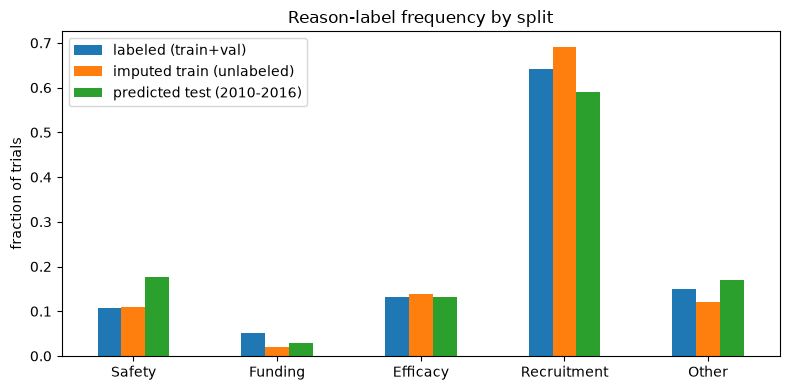

In [9]:
freq = pd.DataFrame({
    'labeled (train+val)': Y_lab_all.mean(0),
    'imputed train (unlabeled)': Y_unl_tr.mean(0),
    'predicted test (2010-2016)': Y_te.mean(0),
}, index=LABELS)
ax = freq.plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel('fraction of trials')
ax.set_title('Reason-label frequency by split')
plt.tight_layout()
plt.savefig('part1_label_frequency.png', dpi=150)
freq.round(3)